In [1]:
# Array library.
import numpy as np
# Make random number generator.
rng = np.random.default_rng()

# Data frame library, to load the survey data.
import pandas as pd
pd.set_option('mode.copy_on_write', True)

# Plotting
import matplotlib.pyplot as plt

# Fancy plots
plt.style.use('fivethirtyeight')

C:\Users\WIN11\AppData\Local\Temp\ipykernel_10188\867608254.py:8: Pandas4Warning: The 'mode.copy_on_write' option is deprecated. Copy-on-Write can no longer be disabled (it is always enabled with pandas >= 3.0), and setting the option has no impact. This option will be removed in pandas 4.0.
  pd.set_option('mode.copy_on_write', True)


In [2]:
# Use Pandas to read the data.
# Don't worry if you aren't confident with Pandas yet - we only
# use Pandas here to get the ages for the Remain and Leave voters.
# Load the data frame, and put it in the variable "brexit_df".
brexit_df = pd.read_csv('data/brexit_survey.csv')
# Show the first 5 rows.
brexit_df.head()

,brexit_vote,age
0,Remain,37
1,Remain,55
2,Leave,71
3,Remain,37
4,Remain,42


In [3]:
# Extract Remain and Leave voters into their separate own data frames.
# As above, we are just using Pandas here to get arrays for the
# Remain and Leave voter ages.
remainers = brexit_df[brexit_df['brexit_vote'] == 'Remain']
leavers = brexit_df[brexit_df['brexit_vote'] == 'Leave']
# Extract ages into arrays.
remain_ages = np.array(remainers['age'])
leave_ages = np.array(leavers['age'])

In [4]:
n_remain = len(remain_ages)
n_remain

774

In [5]:
# Show the first 10 ages for the Remain voters.
remain_ages[:10]

array([37, 55, 37, 42, 69, 20, 38, 32, 58, 46])

In [6]:
n_leave = len(leave_ages)
n_leave

541

In [7]:
# Show the first 10 ages for the Leave voters.
leave_ages[:10]

array([71, 60, 74, 61, 47, 56, 76, 35, 44, 38])

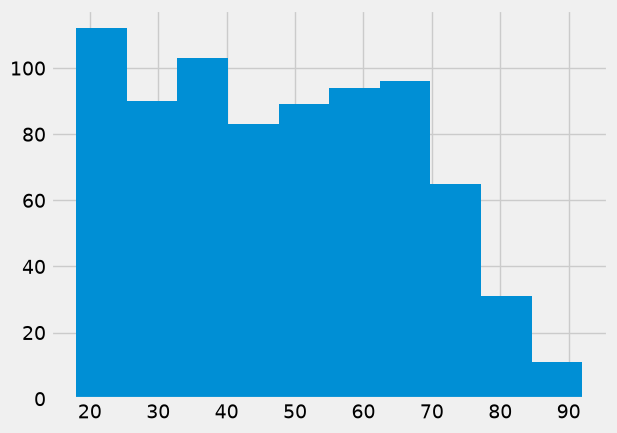

In [8]:
plt.hist(remain_ages);

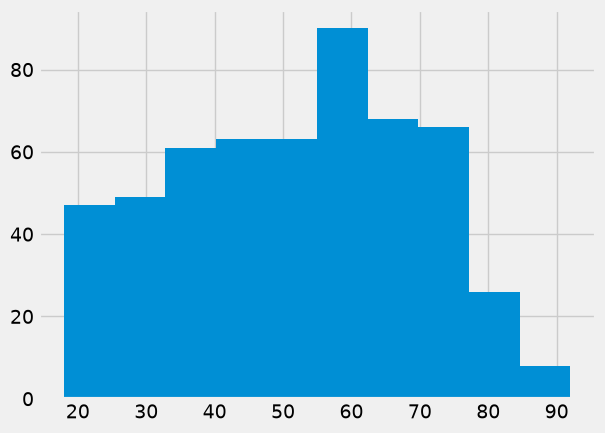

In [9]:
plt.hist(leave_ages);

In [10]:
leave_mean = np.mean(leave_ages)
leave_mean

np.float64(51.715341959334566)

In [11]:
remain_mean = np.mean(remain_ages)
remain_mean

np.float64(48.01550387596899)

In [12]:
actual_difference = leave_mean - remain_mean
actual_difference

np.float64(3.6998380833655773)

In [13]:
pooled = np.concatenate([remain_ages, leave_ages])
pooled

array([37, 55, 37, ..., 20, 40, 31], shape=(1315,))

In [14]:
len(pooled)

1315

In [15]:
pets = np.array(['cat', 'dog', 'rabbit'])
pets

array(['cat', 'dog', 'rabbit'], dtype='<U6')

In [16]:
rng.permutation(pets)

array(['cat', 'rabbit', 'dog'], dtype='<U6')

In [17]:
rng.permutation(pets)

array(['cat', 'dog', 'rabbit'], dtype='<U6')

In [18]:
shuffled = rng.permutation(pooled)
shuffled

array([31, 24, 50, ..., 32, 26, 40], shape=(1315,))

In [19]:
# The first 774 values
fake_remainers = shuffled[:774]
# The rest
fake_leavers = shuffled[774:]
len(fake_leavers)

541

In [20]:
fake_difference = np.mean(fake_leavers) - np.mean(fake_remainers)
fake_difference

np.float64(0.3741348923182741)

In [21]:
shuffled = rng.permutation(pooled)
fake_difference_2 = np.mean(shuffled[:774]) - np.mean(shuffled[774:])
fake_difference_2

np.float64(-1.4952642966656597)

In [22]:
# An array of zeros to store the fake differences
example_diffs = np.zeros(10000)
# Do the shuffle / difference steps 10000 times
for i in np.arange(10000):
    shuffled = rng.permutation(pooled)
    fake_remainers = shuffled[:n_remain]
    fake_leavers = shuffled[n_remain:]
    eg_diff = np.mean(fake_leavers) - np.mean(fake_remainers)
    # Collect the results in the results array
    example_diffs[i] = eg_diff

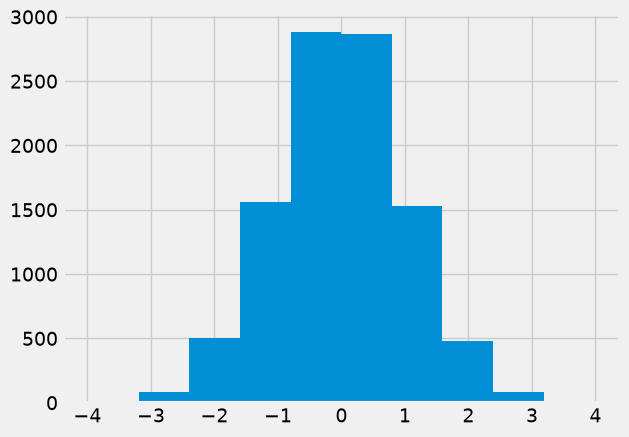

In [23]:
plt.hist(example_diffs);

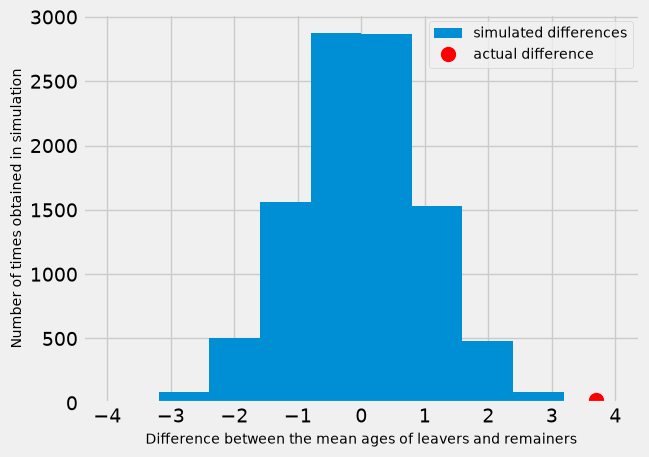

In [24]:
# do not worry about the code below, it just plots the sampling distribution, the actual difference in the mean ages,
# and adds some labels to the histogram.
plt.hist(example_diffs, label = 'simulated differences')
fontsize = {'fontsize': 10}
plt.plot(actual_difference, 20 , 'o',
         markersize = 10,color = 'red',
         label = 'actual difference')
plt.xlabel('Difference between the mean ages of leavers and remainers', **fontsize)
plt.ylabel('Number of times obtained in simulation', **fontsize)
plt.legend(**fontsize);

In [25]:
are_as_high = example_diffs >= actual_difference
n_as_high = np.count_nonzero(are_as_high)
n_as_high

np.int64(1)

In [26]:
proportion = n_as_high / 10000
proportion

np.float64(0.0001)